# Reto Mercadotecnia telefónica con aprendizaje supervisado

**Participante:** José Trinidad Rosales  
**Curso:** Solución de retos con aprendizaje supervisado  
**Archivo:** `Solucion_Reto_SC_63_Jose_Trinidad_Rosales.ipynb`

Este notebook diseña, ajusta y evalúa dos clasificadores para predecir si un cliente
contratará un depósito a plazo después de una campaña telefónica. La comparación usa
validación; el conjunto de prueba permanece aislado hasta la evaluación final.


## Objetivo y evidencia de cumplimiento

El objetivo es estimar la clase positiva `y = yes` con un proceso reproducible y sin
fuga entre entrenamiento, validación y prueba. Se reporta exactitud como el “porcentaje
de predicción” solicitado, pero la decisión se sustenta también con precisión, recall,
F1, ROC-AUC, precisión promedio (AP) y matrices de confusión.

| Criterio de la rúbrica | Evidencia incluida |
|---|---|
| Carga e información de variables | `data`, dimensiones, tipos, cardinalidad, nulos, `unknown`, duplicados, estadística descriptiva y balance de `y` |
| Procesamiento | `OneHotEncoder`, tratamiento de sesgo, escalamiento, historial previo y `Pipeline` ajustado sólo con entrenamiento |
| Partición | 60% entrenamiento, 20% validación y 20% prueba, estratificados y sin solapamiento |
| Dos modelos | Regresión logística y red neuronal, ajuste de hiperparámetros, porcentajes de predicción y matrices de confusión |
| Prueba y conclusiones | Selección con validación, una evaluación final en prueba, interpretación comercial y limitaciones |


## Diccionario de datos

El archivo corresponde al conjunto **Bank Marketing**. Contiene información de campañas
de mercadotecnia directa de una institución bancaria portuguesa. El objetivo es predecir
si el cliente suscribió un depósito a plazo.

| Variable | Tipo | Significado |
|---|---|---|
| `age` | Numérica | Edad del cliente |
| `job` | Categórica | Tipo de ocupación |
| `marital` | Categórica | Estado civil; `divorced` incluye divorcio o viudez |
| `education` | Categórica | Nivel educativo |
| `default` | Categórica | Incumplimiento crediticio (`yes`/`no`) |
| `balance` | Numérica | Saldo anual promedio, en euros |
| `housing` | Categórica | Crédito de vivienda (`yes`/`no`) |
| `loan` | Categórica | Préstamo personal (`yes`/`no`) |
| `contact` | Categórica | Canal del último contacto |
| `day` | Numérica | Día del mes del último contacto |
| `month` | Categórica | Mes del último contacto |
| `duration` | Numérica | Duración del último contacto, en segundos |
| `campaign` | Numérica | Contactos de la campaña actual, incluido el último |
| `pdays` | Numérica | Días desde la campaña previa; `-1` significa nunca contactado |
| `previous` | Numérica | Contactos anteriores a la campaña actual |
| `poutcome` | Categórica | Resultado de la campaña previa |
| `y` | Objetivo | Suscripción del depósito a plazo (`yes`/`no`) |

**Fuente:** S. Moro, P. Rita y P. Cortez, *Bank Marketing*, UCI Machine Learning
Repository, DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306). El diccionario fue
contrastado con el archivo `bank-names-RETO_DS_AS.txt` proporcionado para el reto.


## 1 Configuración y carga de los datos


In [1]:
from pathlib import Path
import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, OneHotEncoder, PowerTransformer, StandardScaler,
)

try:
    from IPython.display import display
except ImportError:
    pass

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"navy": "#0B2E63", "blue": "#2F73B7", "teal": "#0E9F9A", "coral": "#E56B6F"}

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")
print(f"Semilla aleatoria: {RANDOM_STATE}")


Python: 3.12.14
pandas: 2.2.3 | scikit-learn: 1.8.0
Semilla aleatoria: 42


In [2]:
# En Colab se busca primero el nombre entregado. Si no existe, se solicita la carga.
candidate_paths = [
    Path("bank_marketing_RETO_DS_AS(3).csv"),
    Path("bank_marketing_RETO_DS_AS.csv"),
    Path("bank_marketing.csv"),
    Path("/content/bank_marketing_RETO_DS_AS(3).csv"),
    Path("/content/bank_marketing_RETO_DS_AS.csv"),
    Path("/content/bank_marketing.csv"),
    Path("upload/bank_marketing_RETO_DS_AS(3).csv"),  # ruta de la ejecución entregada
]
data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No se cargó un archivo CSV.")
        data_path = Path(csv_names[0])
    except ImportError as exc:
        raise FileNotFoundError(
            "Coloca bank_marketing_RETO_DS_AS.csv junto al notebook."
        ) from exc

# La consigna solicita que el conjunto se almacene en una variable llamada data.
data = pd.read_csv(data_path)
print(f"Archivo cargado: {data_path.name}")
print(f"Dimensiones: {data.shape[0]:,} registros x {data.shape[1]} variables")
display(data.head())


Archivo cargado: bank_marketing_RETO_DS_AS(3).csv
Dimensiones: 9,000 registros x 17 variables


age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
31,self-employed,married,tertiary,no,2666,no,no,cellular,10,nov,318,2,97,6,success,yes
29,unemployed,single,unknown,no,1584,no,no,cellular,6,sep,245,1,-1,0,unknown,yes
41,blue-collar,married,secondary,no,2152,yes,no,cellular,17,nov,369,1,-1,0,unknown,no
50,blue-collar,married,secondary,no,84,yes,no,cellular,17,jul,18,8,-1,0,unknown,no
40,admin.,married,secondary,no,0,no,no,cellular,28,jul,496,2,182,11,success,yes


## 2 Análisis descriptivo y calidad de los datos


In [3]:
variable_profile = pd.DataFrame({
    "variable": data.columns,
    "tipo_pandas": data.dtypes.astype(str).values,
    "rol": ["objetivo" if col == "y" else "entrada" for col in data.columns],
    "clase": ["numérica" if pd.api.types.is_numeric_dtype(data[col]) else "categórica" for col in data.columns],
    "valores_unicos": [data[col].nunique(dropna=False) for col in data.columns],
    "nulos": [data[col].isna().sum() for col in data.columns],
    "unknown": [int((data[col] == "unknown").sum()) if data[col].dtype == "object" else 0 for col in data.columns],
})

numeric_cols = data.drop(columns="y").select_dtypes(include=np.number).columns.tolist()
categorical_cols = data.drop(columns="y").select_dtypes(exclude=np.number).columns.tolist()

print(f"Variables de entrada numéricas: {len(numeric_cols)}")
print(f"Variables de entrada categóricas: {len(categorical_cols)}")
print(f"Nulos técnicos totales: {int(data.isna().sum().sum())}")
print(f"Filas duplicadas exactas: {int(data.duplicated().sum())}")
display(variable_profile)


Variables de entrada numéricas: 7
Variables de entrada categóricas: 9
Nulos técnicos totales: 0
Filas duplicadas exactas: 0


variable,tipo_pandas,rol,clase,valores_unicos,nulos,unknown
age,int64,entrada,numérica,74,0,0
job,object,entrada,categórica,12,0,51
marital,object,entrada,categórica,3,0,0
education,object,entrada,categórica,4,0,377
default,object,entrada,categórica,2,0,0
balance,int64,entrada,numérica,3476,0,0
housing,object,entrada,categórica,2,0,0
loan,object,entrada,categórica,2,0,0
contact,object,entrada,categórica,3,0,1982
day,int64,entrada,numérica,31,0,0


In [4]:
numeric_summary = data[numeric_cols].agg(["count", "mean", "std", "min", "median", "max"]).T
numeric_summary["sesgo"] = data[numeric_cols].skew()
numeric_summary = numeric_summary.reset_index().rename(columns={"index": "variable"})
display(numeric_summary.round(3))

skewed_full = numeric_summary.loc[numeric_summary["sesgo"].abs() > 1, ["variable", "sesgo"]]
print("Variables con |sesgo| > 1:")
display(skewed_full.round(3))


Variables con |sesgo| > 1:


variable,count,mean,std,min,median,max,sesgo
age,"9,000.0000",41.0910,11.6640,18.0000,39.0000,95.0000,0.8010
balance,"9,000.0000","1,482.2630","3,031.0130","-3,058.0000",519.0000,"81,204.0000",7.2800
day,"9,000.0000",15.6200,8.3450,1.0000,15.0000,31.0000,0.1170
duration,"9,000.0000",353.8330,336.9450,3.0000,240.5000,"3,253.0000",2.1840
campaign,"9,000.0000",2.5200,2.7380,1.0000,2.0000,58.0000,5.3930
pdays,"9,000.0000",50.5110,107.6920,-1.0000,-1.0000,850.0000,2.3490
previous,"9,000.0000",0.7890,2.2100,0.0000,0.0000,58.0000,7.6820


variable,sesgo
balance,7.2800
duration,2.1840
campaign,5.3930
pdays,2.3490
previous,7.6820


In [5]:
unknown_rows = []
for col in categorical_cols:
    count = int((data[col] == "unknown").sum())
    if count:
        unknown_rows.append({"variable": col, "unknown": count, "porcentaje": 100 * count / len(data)})
unknown_summary = pd.DataFrame(unknown_rows)

sentinel_count = int((data["pdays"] == -1).sum())
history_consistency = int(((data["pdays"] == -1) & (data["previous"] == 0)).sum())

print("Aunque no hay NaN, 'unknown' representa información no observada y se conserva como categoría explícita.")
display(unknown_summary.round(2))
print(f"pdays = -1 (sin contacto previo): {sentinel_count:,} registros ({sentinel_count/len(data):.2%})")
print(f"Coinciden pdays = -1 y previous = 0: {history_consistency:,} registros")


Aunque no hay NaN, 'unknown' representa información no observada y se conserva como categoría explícita.
pdays = -1 (sin contacto previo): 6,781 registros (75.34%)
Coinciden pdays = -1 y previous = 0: 6,781 registros


variable,unknown,porcentaje
job,51,0.5700
education,377,4.1900
contact,1982,22.0200
poutcome,6783,75.3700


clase,registros,porcentaje
no,5213,57.9200
yes,3787,42.0800


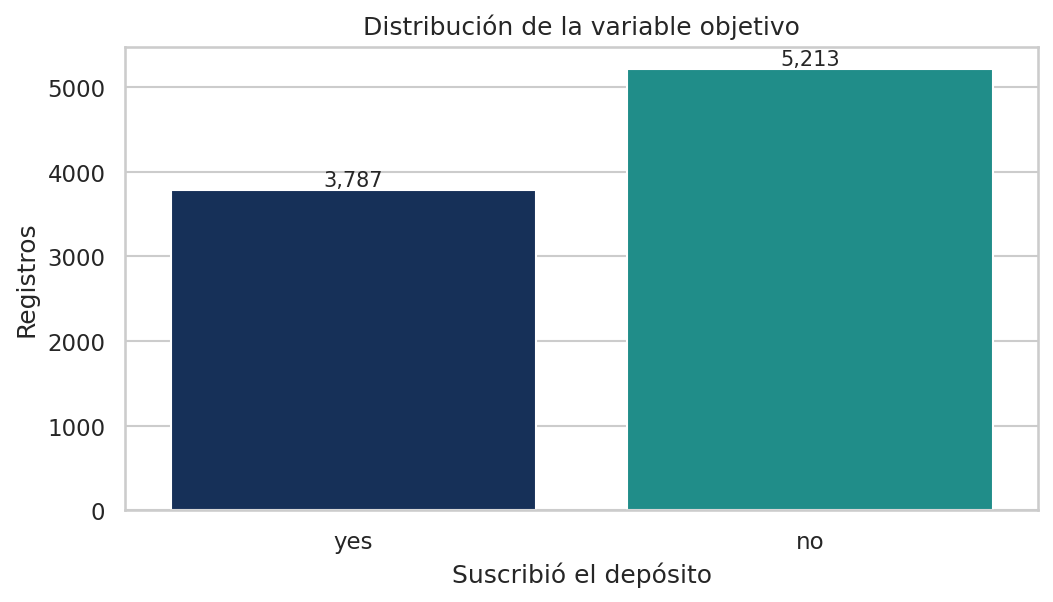

In [6]:
target_summary = (
    data["y"].value_counts()
    .rename_axis("clase")
    .reset_index(name="registros")
)
target_summary["porcentaje"] = 100 * target_summary["registros"] / len(data)
display(target_summary.round(2))

fig, ax = plt.subplots(figsize=(7.2, 4.2))
sns.countplot(data=data, x="y", hue="y", palette=[COLORS["navy"], COLORS["teal"]], legend=False, ax=ax)
ax.set(title="Distribución de la variable objetivo", xlabel="Suscribió el depósito", ylabel="Registros")
for patch in ax.patches:
    ax.annotate(f"{int(patch.get_height()):,}",
                (patch.get_x() + patch.get_width()/2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()


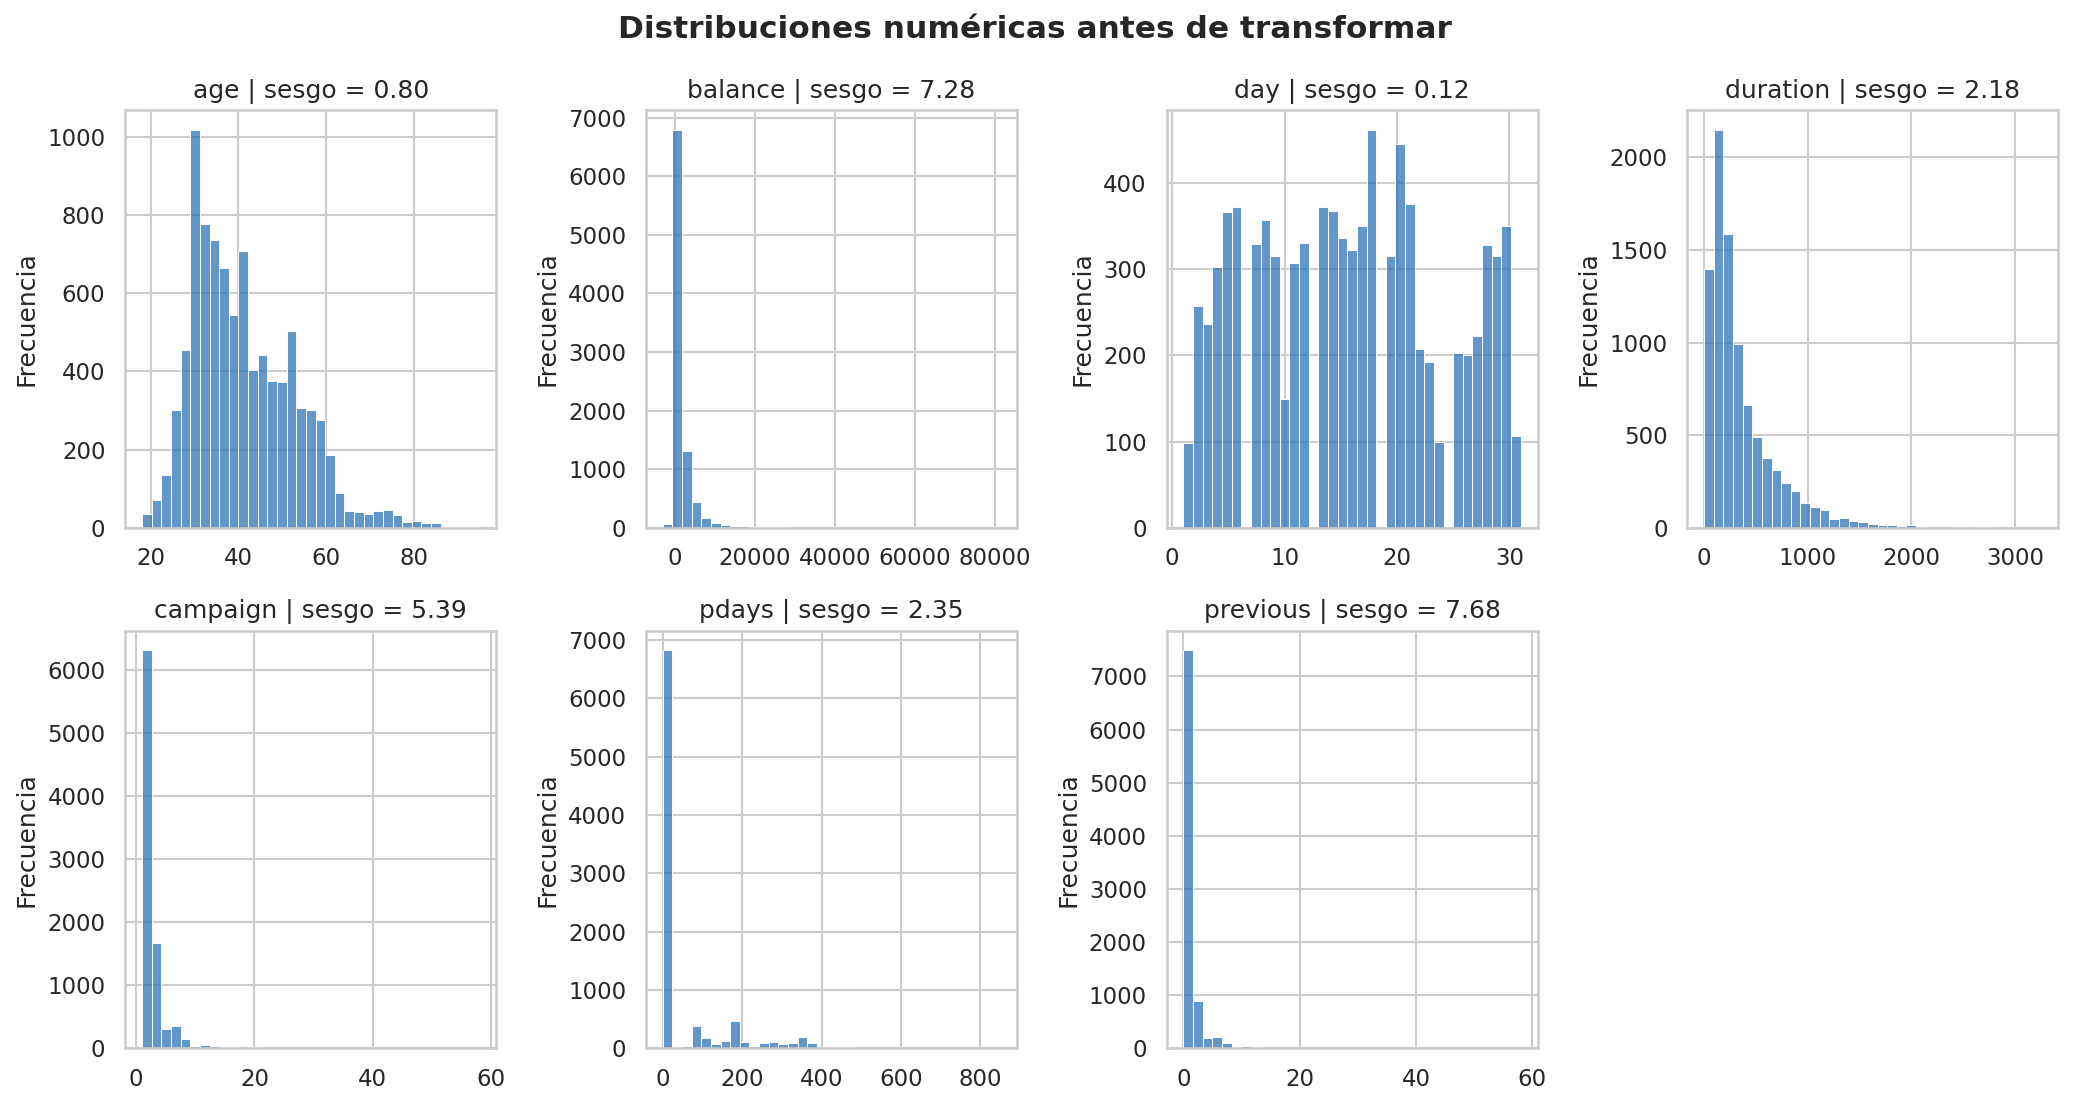

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
axes = axes.ravel()
for ax, col in zip(axes, numeric_cols):
    sns.histplot(data[col], bins=35, color=COLORS["blue"], edgecolor="white", ax=ax)
    ax.set_title(f"{col} | sesgo = {data[col].skew():.2f}")
    ax.set_xlabel("")
    ax.set_ylabel("Frecuencia")
axes[-1].axis("off")
fig.suptitle("Distribuciones numéricas antes de transformar", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## 3 Decisiones de transformación

**Justificación solicitada en el inciso 6.a.** Se usa `OneHotEncoder` para los predictores
categóricos porque `job`, `marital`, `education`, `contact`, `month` y las variables
binarias son nominales. `LabelEncoder` asignaría enteros y crearía distancias u órdenes
artificiales —por ejemplo, que una ocupación “3” sea mayor que una “2”—. `LabelEncoder`
sólo sería razonable para el objetivo binario; por claridad, `y` se mapea directamente
como `no = 0` y `yes = 1`. `handle_unknown='ignore'` permite recibir categorías nuevas.

Las variables numéricas con `|sesgo| > 1` se transforman con Yeo-Johnson, que acepta
ceros y valores negativos, y después quedan estandarizadas. `age` y `day`, con menor
sesgo, reciben `StandardScaler`. El centinela `pdays = -1` se convierte a 0 y se añade
`previously_contacted`; así, 0 días y “nunca contactado” no se confunden. Todo se ajusta
dentro de un `Pipeline` usando únicamente los datos de entrenamiento.

Se conservan `unknown` y los valores extremos: son observaciones posibles y pueden tener
señal. No se aplica SMOTE porque la clase positiva representa 42.08%, un desbalance
moderado. Además, la consigna indica usar `y` como salida y el resto como entradas.


## 4 Partición 60 20 20


In [8]:
X = data.drop(columns="y").copy()
y = data["y"].map({"no": 0, "yes": 1}).astype(int)

# Primer corte: 60% entrenamiento y 40% temporal.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
# Segundo corte: la mitad del temporal para validación y la otra mitad para prueba.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

split_summary = []
for name, features, target in [
    ("Entrenamiento", X_train, y_train),
    ("Validación", X_val, y_val),
    ("Prueba", X_test, y_test),
]:
    split_summary.append({
        "conjunto": name,
        "registros": len(features),
        "porcentaje": 100 * len(features) / len(data),
        "no": int((target == 0).sum()),
        "yes": int((target == 1).sum()),
        "tasa_yes": 100 * target.mean(),
    })
split_summary = pd.DataFrame(split_summary)

assert len(X_train) == 5400 and len(X_val) == 1800 and len(X_test) == 1800
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
display(split_summary.round(2))
print("Comprobación: tres conjuntos estratificados, reproducibles y sin solapamiento.")


Comprobación: tres conjuntos estratificados, reproducibles y sin solapamiento.


conjunto,registros,porcentaje,no,yes,tasa_yes
Entrenamiento,5400,60.0000,3128,2272,42.0700
Validación,1800,20.0000,1042,758,42.1100
Prueba,1800,20.0000,1043,757,42.0600


In [9]:
train_numeric = X_train.select_dtypes(include=np.number).columns.tolist()
train_categorical = X_train.select_dtypes(exclude=np.number).columns.tolist()
train_skewness = X_train[train_numeric].skew()
skewed_numeric = train_skewness[train_skewness.abs() > 1].index.tolist()
regular_numeric = [col for col in train_numeric if col not in skewed_numeric]

transform_plan = pd.DataFrame({
    "grupo": ["Numéricas sesgadas", "Numéricas con menor sesgo", "Categóricas", "Indicador creado"],
    "variables": [
        ", ".join(skewed_numeric),
        ", ".join(regular_numeric),
        ", ".join(train_categorical),
        "previously_contacted",
    ],
    "tratamiento": [
        "Mediana + Yeo-Johnson + estandarización",
        "Mediana + StandardScaler",
        "Moda si hubiera NaN + OneHotEncoder",
        "0/1 a partir de pdays",
    ],
})
display(transform_plan)


grupo,variables,tratamiento
Numéricas sesgadas,"balance, duration, campaign, pdays, previous",Mediana + Yeo-Johnson + estandarización
Numéricas con menor sesgo,"age, day",Mediana + StandardScaler
Categóricas,"job, marital, education, default, housing, loan, contact, month, poutcome",Moda si hubiera NaN + OneHotEncoder
Indicador creado,previously_contacted,0/1 a partir de pdays


In [10]:
def engineer_contact_history(frame):
    # Conserva la información del centinela pdays=-1 dentro del pipeline.
    engineered = frame.copy()
    engineered["previously_contacted"] = (engineered["pdays"] != -1).astype(int)
    engineered["pdays"] = engineered["pdays"].mask(engineered["pdays"] == -1, 0)
    return engineered


def make_preprocessor(reference_frame):
    numeric = reference_frame.select_dtypes(include=np.number).columns.tolist()
    categorical = reference_frame.select_dtypes(exclude=np.number).columns.tolist()
    skewness = reference_frame[numeric].skew()
    skewed = skewness[skewness.abs() > 1].index.tolist()
    regular = [col for col in numeric if col not in skewed]

    # Compatibilidad con versiones antiguas y nuevas de scikit-learn en Colab.
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    column_steps = ColumnTransformer(
        transformers=[
            ("skewed", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("power", PowerTransformer(method="yeo-johnson", standardize=True)),
            ]), skewed),
            ("regular", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), regular),
            ("history_flag", "passthrough", ["previously_contacted"]),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", encoder),
            ]), categorical),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return Pipeline([
        ("history", FunctionTransformer(engineer_contact_history, validate=False)),
        ("columns", column_steps),
    ])


preprocessing_check = make_preprocessor(X_train)
X_train_check = preprocessing_check.fit_transform(X_train)
print(f"Forma original de entrenamiento: {X_train.shape}")
print(f"Forma transformada: {X_train_check.shape}")
print(f"Valores finitos: {bool(np.isfinite(X_train_check).all())}")


Forma original de entrenamiento: (5400, 16)
Forma transformada: (5400, 52)
Valores finitos: True


## 5 Funciones de evaluación y línea base


In [11]:
def classification_metrics(y_true, probabilities, threshold=0.50):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def best_f1_threshold(y_true, probabilities):
    rows = []
    for threshold in np.round(np.arange(0.20, 0.71, 0.01), 2):
        metrics = classification_metrics(y_true, probabilities, threshold)
        rows.append(metrics)
    return max(rows, key=lambda row: (row["f1"], row["accuracy"], row["roc_auc"]))


def metrics_table(metrics):
    labels = {
        "threshold": "Umbral", "accuracy": "Exactitud", "balanced_accuracy": "Exactitud balanceada",
        "precision": "Precisión yes", "recall": "Recall yes", "specificity": "Especificidad no",
        "f1": "F1 yes", "roc_auc": "ROC-AUC", "pr_auc": "Average Precision (AP)",
    }
    return pd.DataFrame([
        {"métrica": labels[key], "valor": metrics[key]}
        for key in labels
    ])


def plot_confusion_pair(metrics, title):
    counts = np.array([[metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]]])
    normalized = counts / counts.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
    sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["no", "yes"], yticklabels=["no", "yes"], ax=axes[0])
    axes[0].set(title=f"{title} - conteos", xlabel="Predicción", ylabel="Real")
    sns.heatmap(normalized, annot=True, fmt=".1%", cmap="GnBu", cbar=False, vmin=0, vmax=1,
                xticklabels=["no", "yes"], yticklabels=["no", "yes"], ax=axes[1])
    axes[1].set(title=f"{title} - por clase", xlabel="Predicción", ylabel="Real")
    plt.tight_layout()
    plt.show()


dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_prob = dummy.predict_proba(X_val)[:, 1]
dummy_metrics = classification_metrics(y_val, dummy_prob, threshold=0.50)
print(f"Línea base por clase mayoritaria - exactitud: {dummy_metrics['accuracy']:.2%}; F1 yes: {dummy_metrics['f1']:.2%}")


Línea base por clase mayoritaria - exactitud: 57.89%; F1 yes: 0.00%


## 6 Modelo 1 Regresión logística

Se prueban cuatro intensidades de regularización `C` y dos opciones de ponderación. Para
cada configuración, el umbral se elige en validación maximizando F1 de `yes`; esta elección
prioriza recuperar clientes propensos sin ignorar la precisión. La prueba no interviene.


In [12]:
logistic_records = []
logistic_candidates = []

for params in ParameterGrid({"C": [0.01, 0.1, 1.0, 10.0], "class_weight": [None, "balanced"]}):
    pipeline = Pipeline([
        ("preprocess", make_preprocessor(X_train)),
        ("model", LogisticRegression(
            solver="liblinear", max_iter=2000, random_state=RANDOM_STATE, **params
        )),
    ])
    pipeline.fit(X_train, y_train)
    probabilities = pipeline.predict_proba(X_val)[:, 1]
    metrics = best_f1_threshold(y_val, probabilities)
    logistic_candidates.append({"params": params, "model": pipeline, "metrics": metrics})
    logistic_records.append({
        "C": params["C"],
        "class_weight": str(params["class_weight"]),
        "umbral": metrics["threshold"],
        "exactitud": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "F1": metrics["f1"],
        "ROC_AUC": metrics["roc_auc"],
    })

best_logistic = max(
    logistic_candidates,
    key=lambda item: (item["metrics"]["f1"], item["metrics"]["roc_auc"]),
)
logistic_search = pd.DataFrame(logistic_records).sort_values(["F1", "ROC_AUC"], ascending=False)
display(logistic_search.round(4))
print(f"Mejor configuración: {best_logistic['params']}; umbral = {best_logistic['metrics']['threshold']:.2f}")


Mejor configuración: {'C': 1.0, 'class_weight': None}; umbral = 0.31


C,class_weight,umbral,exactitud,precision,recall,F1,ROC_AUC
1.0000,None,0.3100,0.8239,0.7348,0.9103,0.8132,0.9080
10.0000,None,0.3100,0.8239,0.7348,0.9103,0.8132,0.9079
1.0000,balanced,0.3800,0.8239,0.7353,0.9090,0.8130,0.9081
10.0000,balanced,0.4900,0.8339,0.7755,0.8522,0.8121,0.9080
0.1000,None,0.3300,0.8222,0.7335,0.9077,0.8113,0.9079
0.1000,balanced,0.4300,0.8256,0.7467,0.8865,0.8106,0.9079
0.0100,None,0.4400,0.8289,0.7704,0.8456,0.8063,0.9027
0.0100,balanced,0.5100,0.8267,0.7674,0.8443,0.8040,0.9026


Porcentaje de predicción correcto en validación (exactitud): 82.39%


métrica,valor
Umbral,0.3100
Exactitud,0.8239
Exactitud balanceada,0.8357
Precisión yes,0.7348
Recall yes,0.9103
Especificidad no,0.7610
F1 yes,0.8132
ROC-AUC,0.9080
Average Precision (AP),0.8624


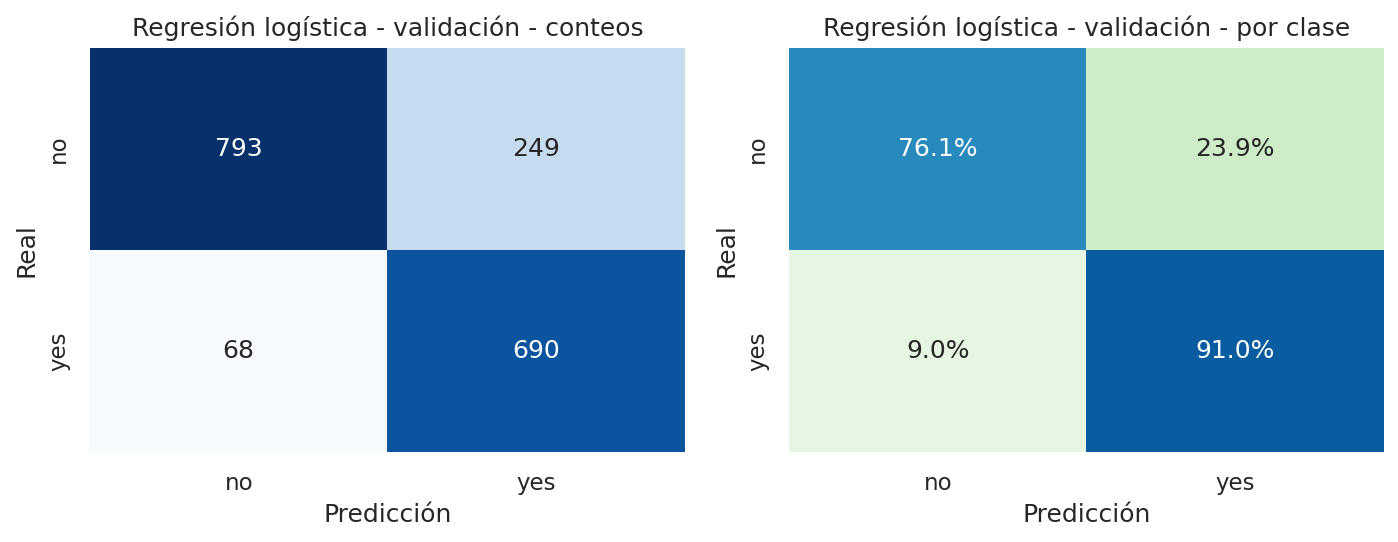

In [13]:
logistic_metrics = best_logistic["metrics"]
display(metrics_table(logistic_metrics).round(4))
print("Porcentaje de predicción correcto en validación "
      f"(exactitud): {logistic_metrics['accuracy']:.2%}")
plot_confusion_pair(logistic_metrics, "Regresión logística - validación")


## 7 Modelo 2 Red neuronal

La red es un `MLPClassifier`. Se comparan una y dos capas ocultas, de 16 a 64 neuronas,
y distintos niveles de regularización `alpha`. `early_stopping=True` reserva internamente
15% del entrenamiento para detener el ajuste cuando deja de mejorar. La validación externa
sigue siendo la referencia común para comparar los dos modelos.


In [14]:
mlp_grid = [
    {"hidden_layer_sizes": (16,), "alpha": 0.0001},
    {"hidden_layer_sizes": (32,), "alpha": 0.0001},
    {"hidden_layer_sizes": (32, 16), "alpha": 0.0001},
    {"hidden_layer_sizes": (64, 32), "alpha": 0.0001},
    {"hidden_layer_sizes": (32,), "alpha": 0.001},
    {"hidden_layer_sizes": (32, 16), "alpha": 0.001},
    {"hidden_layer_sizes": (64, 32), "alpha": 0.001},
    {"hidden_layer_sizes": (64, 32), "alpha": 0.01},
]

mlp_records = []
mlp_candidates = []
for params in mlp_grid:
    pipeline = Pipeline([
        ("preprocess", make_preprocessor(X_train)),
        ("model", MLPClassifier(
            activation="relu", solver="adam", learning_rate_init=0.001,
            max_iter=500, batch_size=128, early_stopping=True,
            validation_fraction=0.15, n_iter_no_change=20,
            random_state=RANDOM_STATE, **params,
        )),
    ])
    pipeline.fit(X_train, y_train)
    probabilities = pipeline.predict_proba(X_val)[:, 1]
    metrics = best_f1_threshold(y_val, probabilities)
    iterations = pipeline.named_steps["model"].n_iter_
    mlp_candidates.append({"params": params, "model": pipeline, "metrics": metrics})
    mlp_records.append({
        "capas_ocultas": str(params["hidden_layer_sizes"]),
        "alpha": params["alpha"],
        "iteraciones": iterations,
        "umbral": metrics["threshold"],
        "exactitud": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "F1": metrics["f1"],
        "ROC_AUC": metrics["roc_auc"],
    })

best_mlp = max(
    mlp_candidates,
    key=lambda item: (item["metrics"]["f1"], item["metrics"]["roc_auc"]),
)
mlp_search = pd.DataFrame(mlp_records).sort_values(["F1", "ROC_AUC"], ascending=False)
display(mlp_search.round(4))
print(f"Mejor configuración: {best_mlp['params']}; umbral = {best_mlp['metrics']['threshold']:.2f}")


Mejor configuración: {'hidden_layer_sizes': (32,), 'alpha': 0.001}; umbral = 0.39


capas_ocultas,alpha,iteraciones,umbral,exactitud,precision,recall,F1,ROC_AUC
"(32,)",0.0010,74,0.3900,0.8517,0.7806,0.9011,0.8365,0.9171
"(32,)",0.0001,66,0.4400,0.8539,0.7936,0.8826,0.8357,0.9167
"(64, 32)",0.0100,44,0.3300,0.8478,0.7719,0.9063,0.8337,0.9196
"(64, 32)",0.0010,46,0.4500,0.8522,0.7929,0.8786,0.8335,0.9206
"(32, 16)",0.0001,79,0.2700,0.8450,0.7617,0.9195,0.8332,0.9158
"(64, 32)",0.0001,39,0.3000,0.8417,0.7529,0.9288,0.8317,0.9200
"(32, 16)",0.0010,95,0.4300,0.8506,0.7971,0.8654,0.8299,0.9141
"(16,)",0.0001,78,0.4300,0.8378,0.7672,0.8826,0.8209,0.9124


Porcentaje de predicción correcto en validación (exactitud): 85.17%


métrica,valor
Umbral,0.3900
Exactitud,0.8517
Exactitud balanceada,0.8584
Precisión yes,0.7806
Recall yes,0.9011
Especificidad no,0.8157
F1 yes,0.8365
ROC-AUC,0.9171
Average Precision (AP),0.8667


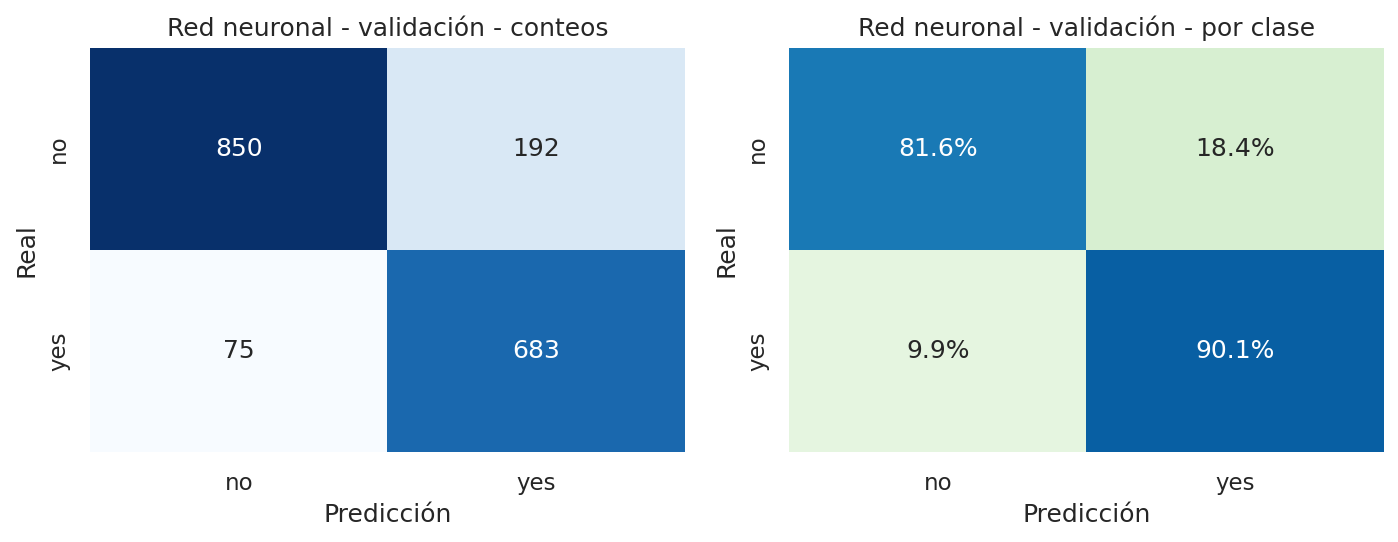

In [15]:
mlp_metrics = best_mlp["metrics"]
display(metrics_table(mlp_metrics).round(4))
print("Porcentaje de predicción correcto en validación "
      f"(exactitud): {mlp_metrics['accuracy']:.2%}")
plot_confusion_pair(mlp_metrics, "Red neuronal - validación")


## 8 Comparación y selección con validación


Modelo seleccionado sin consultar prueba: Red neuronal
Criterio principal: mayor F1 de yes; desempate con ROC-AUC.


modelo,umbral,exactitud,precision,recall,F1,ROC_AUC,AP
Regresión logística,0.3100,0.8239,0.7348,0.9103,0.8132,0.9080,0.8624
Red neuronal,0.3900,0.8517,0.7806,0.9011,0.8365,0.9171,0.8667


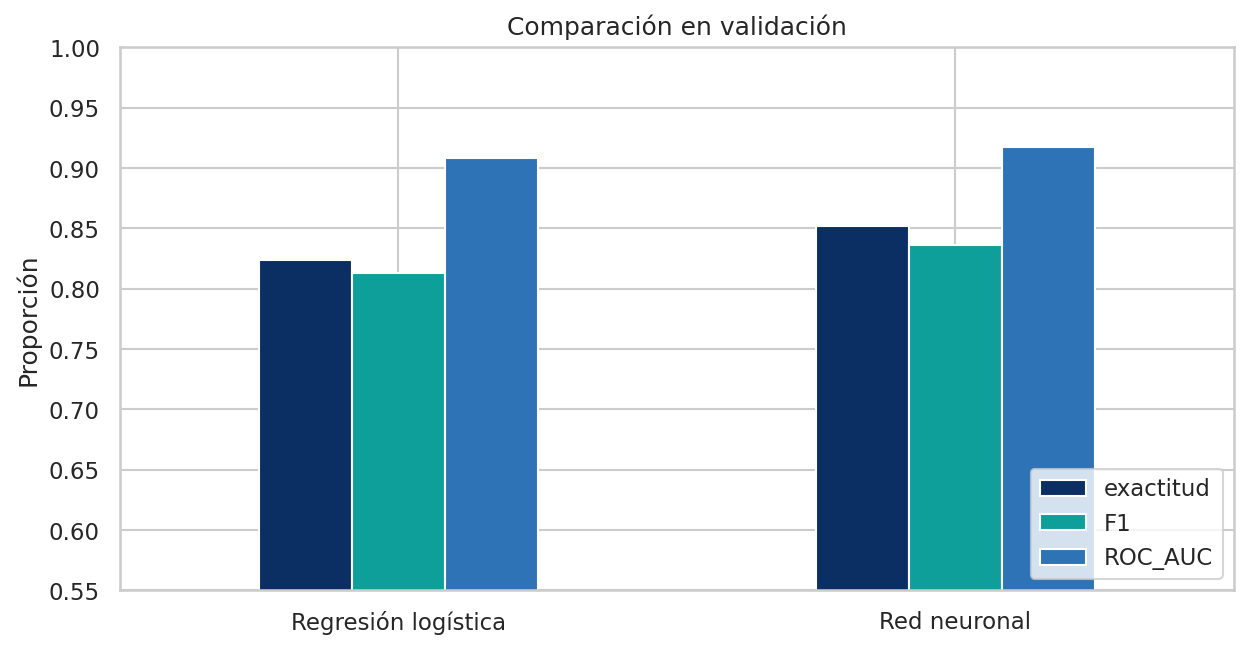

In [16]:
comparison = pd.DataFrame([
    {"modelo": "Regresión logística", **{k: logistic_metrics[k] for k in [
        "threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"
    ]}},
    {"modelo": "Red neuronal", **{k: mlp_metrics[k] for k in [
        "threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"
    ]}},
]).rename(columns={
    "threshold": "umbral", "accuracy": "exactitud", "precision": "precision",
    "recall": "recall", "f1": "F1", "roc_auc": "ROC_AUC", "pr_auc": "AP",
})
display(comparison.round(4))

mlp_score = (mlp_metrics["f1"], mlp_metrics["roc_auc"])
logistic_score = (logistic_metrics["f1"], logistic_metrics["roc_auc"])
if mlp_score > logistic_score:
    selected_name = "Red neuronal"
    selected_candidate = best_mlp
else:
    selected_name = "Regresión logística"
    selected_candidate = best_logistic
selected_threshold = selected_candidate["metrics"]["threshold"]

chart_data = comparison.set_index("modelo")[["exactitud", "F1", "ROC_AUC"]]
chart_data.plot(kind="bar", figsize=(8.5, 4.5), color=[COLORS["navy"], COLORS["teal"], COLORS["blue"]])
plt.ylim(0.55, 1.0)
plt.ylabel("Proporción")
plt.xlabel("")
plt.title("Comparación en validación")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Modelo seleccionado sin consultar prueba: {selected_name}")
print(f"Criterio principal: mayor F1 de yes; desempate con ROC-AUC.")


variable,disminucion_ROC_AUC,desviacion
duration,0.2472,0.0097
month,0.0476,0.0040
contact,0.0298,0.0036
poutcome,0.0130,0.0024
housing,0.0109,0.0012
previous,0.0075,0.0014
day,0.0065,0.0014
pdays,0.0024,0.0008
age,0.0019,0.0011
education,0.0019,0.0007


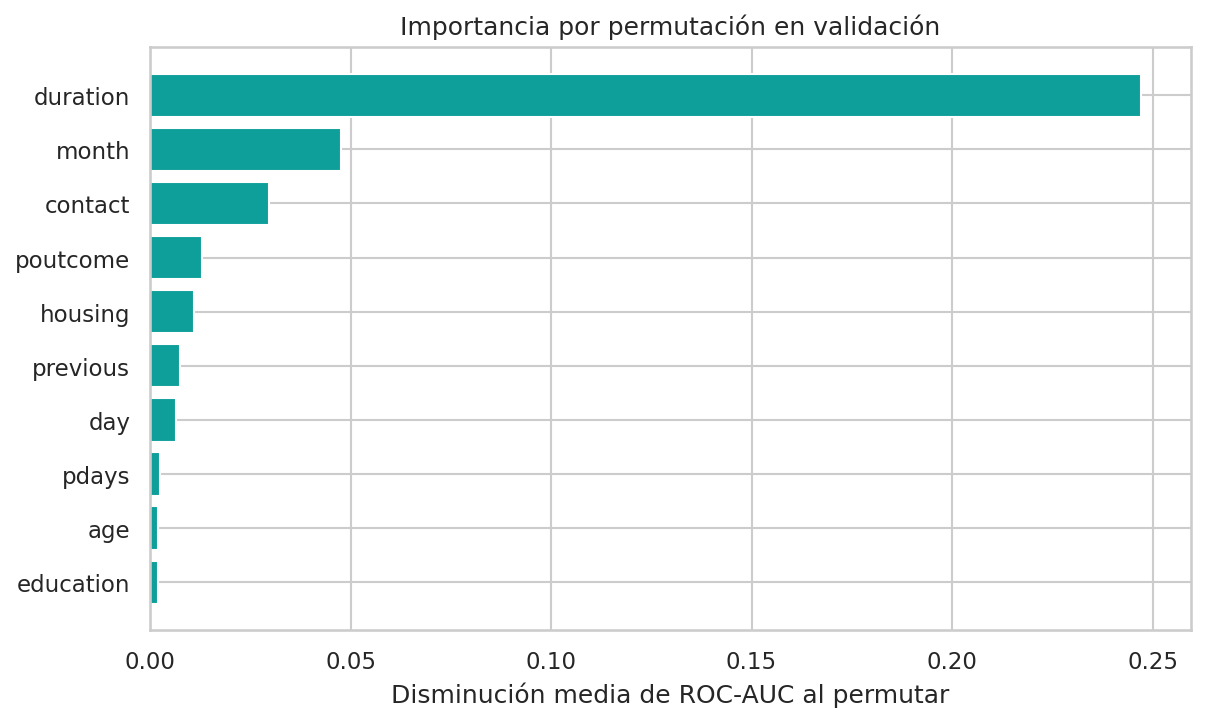

In [17]:
selected_validation_model = selected_candidate["model"]
importance = permutation_importance(
    selected_validation_model, X_val, y_val,
    scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_table = pd.DataFrame({
    "variable": X_val.columns,
    "disminucion_ROC_AUC": importance.importances_mean,
    "desviacion": importance.importances_std,
}).sort_values("disminucion_ROC_AUC", ascending=False)
display(importance_table.round(4))

top_importance = importance_table.head(10).sort_values("disminucion_ROC_AUC")
plt.figure(figsize=(8.2, 5.0))
plt.barh(top_importance["variable"], top_importance["disminucion_ROC_AUC"], color=COLORS["teal"])
plt.xlabel("Disminución media de ROC-AUC al permutar")
plt.title("Importancia por permutación en validación")
plt.tight_layout()
plt.show()


## 9 Comprobación operativa sin duration

`duration` sólo se conoce al terminar la llamada. Se incluye en los dos modelos principales
para respetar la instrucción de usar el resto de las variables como entradas, pero un modelo
para decidir **a quién llamar antes de llamar** no puede usarla. La siguiente ablación vuelve
a entrenar la configuración ganadora sin `duration`; no es un tercer modelo de la rúbrica,
sino una prueba de la limitación temporal.


In [18]:
def build_selected_model(reference_frame, name, params):
    if name == "Red neuronal":
        estimator = MLPClassifier(
            activation="relu", solver="adam", learning_rate_init=0.001,
            max_iter=500, batch_size=128, early_stopping=True,
            validation_fraction=0.15, n_iter_no_change=20,
            random_state=RANDOM_STATE, **params,
        )
    else:
        estimator = LogisticRegression(
            solver="liblinear", max_iter=2000,
            random_state=RANDOM_STATE, **params,
        )
    return Pipeline([
        ("preprocess", make_preprocessor(reference_frame)),
        ("model", estimator),
    ])


X_train_no_duration = X_train.drop(columns="duration")
X_val_no_duration = X_val.drop(columns="duration")
no_duration_model = build_selected_model(
    X_train_no_duration, selected_name, selected_candidate["params"]
)
no_duration_model.fit(X_train_no_duration, y_train)
no_duration_prob = no_duration_model.predict_proba(X_val_no_duration)[:, 1]
no_duration_metrics = best_f1_threshold(y_val, no_duration_prob)

duration_comparison = pd.DataFrame([
    {
        "escenario": "Con duration (académico)",
        "umbral": selected_candidate["metrics"]["threshold"],
        "exactitud": selected_candidate["metrics"]["accuracy"],
        "F1": selected_candidate["metrics"]["f1"],
        "ROC_AUC": selected_candidate["metrics"]["roc_auc"],
    },
    {
        "escenario": "Sin duration (pre-llamada)",
        "umbral": no_duration_metrics["threshold"],
        "exactitud": no_duration_metrics["accuracy"],
        "F1": no_duration_metrics["f1"],
        "ROC_AUC": no_duration_metrics["roc_auc"],
    },
])
display(duration_comparison.round(4))
print("La caída confirma que duration aporta señal posterior a la llamada y no debe usarse para priorización previa.")


La caída confirma que duration aporta señal posterior a la llamada y no debe usarse para priorización previa.


escenario,umbral,exactitud,F1,ROC_AUC
Con duration (académico),0.3900,0.8517,0.8365,0.9171
Sin duration (pre-llamada),0.3200,0.6733,0.6674,0.7676


## 10 Evaluación final única en prueba


In [19]:
# Después de fijar modelo, hiperparámetros y umbral, se reincorpora validación al ajuste.
X_train_validation = pd.concat([X_train, X_val], axis=0)
y_train_validation = pd.concat([y_train, y_val], axis=0)

final_model = build_selected_model(
    X_train_validation, selected_name, selected_candidate["params"]
)
final_model.fit(X_train_validation, y_train_validation)

# El conjunto de prueba no se usó para entrenar, ajustar ni seleccionar el modelo.
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_metrics = classification_metrics(y_test, test_probabilities, selected_threshold)
test_predictions = (test_probabilities >= selected_threshold).astype(int)

print(f"Modelo final: {selected_name}")
print(f"Umbral fijado en validación: {selected_threshold:.2f}")
print(f"Registros usados para reajuste: {len(X_train_validation):,}")
display(metrics_table(test_metrics).round(4))
print(f"Porcentaje de predicción correcto en prueba (exactitud): {test_metrics['accuracy']:.2%}")


Modelo final: Red neuronal
Umbral fijado en validación: 0.39
Registros usados para reajuste: 7,200
Porcentaje de predicción correcto en prueba (exactitud): 84.22%


métrica,valor
Umbral,0.3900
Exactitud,0.8422
Exactitud balanceada,0.8501
Precisión yes,0.7660
Recall yes,0.8996
Especificidad no,0.8006
F1 yes,0.8275
ROC-AUC,0.9198
Average Precision (AP),0.8727


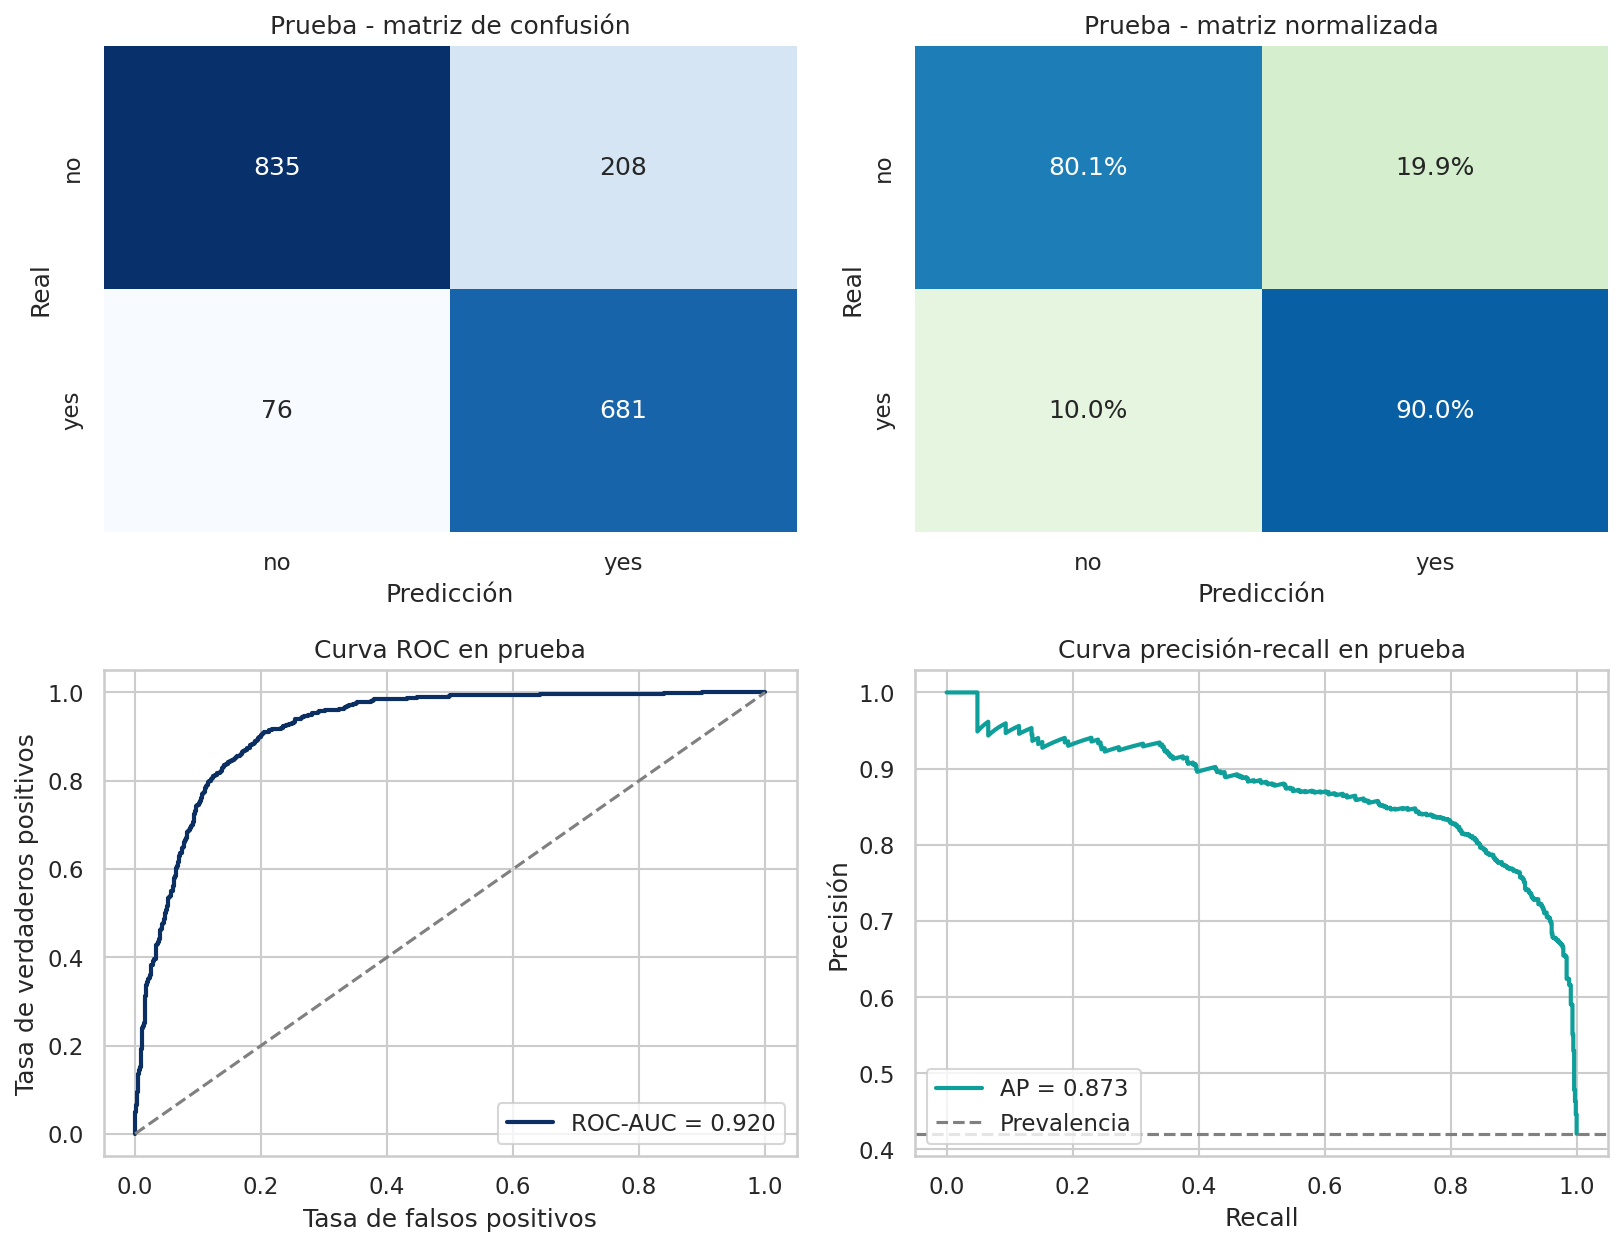

In [20]:
counts = np.array([[test_metrics["tn"], test_metrics["fp"]],
                   [test_metrics["fn"], test_metrics["tp"]]])
normalized = counts / counts.sum(axis=1, keepdims=True)
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
pr_precision, pr_recall, _ = precision_recall_curve(y_test, test_probabilities)

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["no", "yes"], yticklabels=["no", "yes"], ax=axes[0, 0])
axes[0, 0].set(title="Prueba - matriz de confusión", xlabel="Predicción", ylabel="Real")

sns.heatmap(normalized, annot=True, fmt=".1%", cmap="GnBu", cbar=False, vmin=0, vmax=1,
            xticklabels=["no", "yes"], yticklabels=["no", "yes"], ax=axes[0, 1])
axes[0, 1].set(title="Prueba - matriz normalizada", xlabel="Predicción", ylabel="Real")

axes[1, 0].plot(fpr, tpr, color=COLORS["navy"], lw=2,
                label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}")
axes[1, 0].plot([0, 1], [0, 1], "--", color="gray")
axes[1, 0].set(title="Curva ROC en prueba", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
axes[1, 0].legend(loc="lower right")

axes[1, 1].plot(pr_recall, pr_precision, color=COLORS["teal"], lw=2,
                label=f"AP = {test_metrics['pr_auc']:.3f}")
axes[1, 1].axhline(y_test.mean(), ls="--", color="gray", label="Prevalencia")
axes[1, 1].set(title="Curva precisión-recall en prueba", xlabel="Recall", ylabel="Precisión")
axes[1, 1].legend(loc="lower left")

plt.tight_layout()
plt.show()


## 11 Perfil descriptivo de los clientes con mayor respuesta


In [21]:
# Se usa sólo entrenamiento para no convertir prueba en una fuente de decisiones.
train_profile = X_train.copy()
train_profile["target"] = y_train
profile_rows = []
for variable in ["poutcome", "contact", "housing", "loan", "job", "education", "month"]:
    rates = (
        train_profile.groupby(variable)["target"]
        .agg(tasa_yes="mean", registros="size")
        .query("registros >= 30")
        .sort_values("tasa_yes", ascending=False)
        .head(3)
    )
    for level, row in rates.iterrows():
        profile_rows.append({
            "variable": variable,
            "categoría": level,
            "registros_train": int(row["registros"]),
            "tasa_yes_train": row["tasa_yes"],
        })
profile_table = pd.DataFrame(profile_rows)
display(profile_table.round(4))

medians_by_target = (
    train_profile.groupby("target")[["age", "balance", "day", "duration", "campaign", "pdays", "previous"]]
    .median().T.rename(columns={0: "mediana_no", 1: "mediana_yes"}).reset_index()
    .rename(columns={"index": "variable"})
)
display(medians_by_target.round(2))


variable,categoría,registros_train,tasa_yes_train
poutcome,success,451,0.9091
poutcome,other,271,0.5166
poutcome,failure,567,0.4321
contact,cellular,3849,0.4884
contact,telephone,351,0.4815
contact,unknown,1200,0.1858
housing,no,2742,0.5284
housing,yes,2658,0.3096
loan,no,4704,0.4405
loan,yes,696,0.2874


target,variable,mediana_no,mediana_yes
,age,39.0000,38.0000
,balance,393.0000,756.5000
,day,16.0000,15.0000
,duration,163.0000,431.5000
,campaign,2.0000,2.0000
,pdays,-1.0000,-1.0000
,previous,0.0000,0.0000


## 12 Conclusiones

1. **La red neuronal fue el mejor modelo en validación.** Con una capa de 32 neuronas,
   `alpha = 0.001` y umbral 0.39 obtuvo 85.17% de exactitud, F1 de 0.8365 y ROC-AUC de
   0.9171. La regresión logística obtuvo 82.39% de exactitud, F1 de 0.8132 y ROC-AUC de
   0.9080. La selección se hizo antes de consultar prueba.

2. **El resultado final generaliza razonablemente.** Tras reajustar la red con
   entrenamiento más validación, la prueba independiente alcanzó 84.22% de exactitud,
   76.60% de precisión, 89.96% de recall, F1 de 0.8275, ROC-AUC de 0.9198 y AP de
   0.8727. La matriz final contiene 835 verdaderos negativos, 208 falsos positivos,
   76 falsos negativos y 681 verdaderos positivos. El modelo identifica cerca de nueve
   de cada diez suscripciones observadas y clasifica como posibles suscriptores a 208
   clientes que finalmente no contrataron.

3. **La IA puede apoyar la mercadotecnia mediante priorización, no demostrar causalidad.**
   En entrenamiento se observan mayores tasas de respuesta cuando `poutcome=success`,
   cuando no existe crédito de vivienda o préstamo personal y en algunos segmentos como
   estudiantes y jubilados. Son asociaciones de esta muestra; no prueban que modificar
   una característica cause la compra.

4. **`duration` cambia el momento de uso.** Su importancia por permutación domina el
   modelo, pero sólo se conoce al finalizar la conversación. Al excluirla, el ROC-AUC de
   validación baja aproximadamente de 0.917 a 0.768. Por tanto, el modelo principal es
   útil como predicción posterior o referencia académica; para seleccionar clientes antes
   de llamar debe desplegarse y validarse una versión sin `duration`.

5. **No puede afirmarse que la campaña sea rentable sólo con estos datos.** El archivo del
   reto tiene 42.08% de positivos, una proporción distinta a la base UCI completa, y no
   aporta costos de contacto, margen del producto, identificador de cliente ni fecha
   completa. Para producción se necesita validación temporal, calibración con la
   prevalencia real, análisis de costos, monitoreo de deriva y revisión de sesgos por grupo.

En síntesis, el aprendizaje supervisado permite concentrar esfuerzos comerciales y medir
de forma explícita los errores. Su valor depende de definir el momento de predicción, el
costo de falsos positivos y falsos negativos, y una evaluación prospectiva antes del uso.
